In [1]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
df = pd.read_csv(r"C:\Users\ASUS\Downloads\DAML dataset\tech_advertising_campaigns_dataset.csv")

print("Dataset shape:", df.shape)

Dataset shape: (10000, 41)


In [3]:
df["ROI"] = (
    (df["revenue"] - df["ad_spend"])
    / df["ad_spend"]
) * 100

print(df["ROI"].describe())

count    10000.000000
mean       652.494367
std       1498.516912
min       -100.000000
25%         19.679746
50%        214.644531
75%        695.258541
max      48630.026371
Name: ROI, dtype: float64


In [4]:
df_model = df.drop(columns=["campaign_id"]).copy()

# Convert start_date to datetime
df_model["start_date"] = pd.to_datetime(df_model["start_date"])

# Create date-based features
df_model["start_year"] = df_model["start_date"].dt.year
df_model["start_month"] = df_model["start_date"].dt.month
df_model["start_day"] = df_model["start_date"].dt.day

# Remove original date column
df_model = df_model.drop(columns=["start_date"])

# Convert Boolean features to 0/1
boolean_features = [
    "has_call_to_action",
    "retargeting_flag"
]

for column in boolean_features:
    df_model[column] = df_model[column].astype(int)

print("Prepared dataset shape:", df_model.shape)

Prepared dataset shape: (10000, 43)


In [5]:
leakage_columns = [
    "ROI",
    "revenue",
    "profit",
    "ROAS"
]

X = df_model.drop(columns=leakage_columns)
y = df_model["ROI"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 39)
y shape: (10000,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8000, 39)
X_test: (2000, 39)
y_train: (8000,)
y_test: (2000,)


In [7]:
# Load Saved Preprocessor
preprocessor = joblib.load("../models/preprocessor.pkl")

print("Preprocessor loaded successfully.")

Preprocessor loaded successfully.


In [8]:
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train processed shape:", X_train_processed.shape)
print("X_test processed shape:", X_test_processed.shape)

X_train processed shape: (8000, 106)
X_test processed shape: (2000, 106)


In [9]:
linear_model = LinearRegression()

linear_model.fit(
    X_train_processed,
    y_train
)

print("Linear Regression trained successfully.")

Linear Regression trained successfully.


In [10]:
y_pred_linear = linear_model.predict(X_test_processed)

print("Predictions generated successfully.")
print("\nFirst 10 predicted ROI values:")
print(y_pred_linear[:10])

Predictions generated successfully.

First 10 predicted ROI values:
[-429.78648649   96.93991247  431.40235257  788.01484901 1072.83394418
 -955.70803338 -188.7863277  1192.17185602  356.9253326  1319.45376208]


In [11]:
mae_linear = mean_absolute_error(y_test, y_pred_linear)

rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Performance")
print("--------------------------------")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression Performance
--------------------------------
MAE : 547.8698920248407
RMSE: 1437.5903990793954
R²  : 0.3702224339516542


In [12]:
tree_model = DecisionTreeRegressor(
    random_state=42
)

tree_model.fit(
    X_train_processed,
    y_train
)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [13]:
y_pred_tree = tree_model.predict(X_test_processed)

mae_tree = mean_absolute_error(y_test, y_pred_tree)

rmse_tree = np.sqrt(
    mean_squared_error(y_test, y_pred_tree)
)

r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Performance")
print("--------------------------------")
print("MAE :", mae_tree)
print("RMSE:", rmse_tree)
print("R²  :", r2_tree)

Decision Tree Performance
--------------------------------
MAE : 338.2386982017074
RMSE: 1233.525164757485
R²  : 0.5363258479658131


In [14]:
forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [15]:
y_pred_forest = forest_model.predict(X_test_processed)

mae_forest = mean_absolute_error(y_test, y_pred_forest)

rmse_forest = np.sqrt(
    mean_squared_error(y_test, y_pred_forest)
)

r2_forest = r2_score(y_test, y_pred_forest)

print("Random Forest Performance")
print("--------------------------------")
print("MAE :", mae_forest)
print("RMSE:", rmse_forest)
print("R²  :", r2_forest)

Random Forest Performance
--------------------------------
MAE : 256.1847166586287
RMSE: 1027.2636115165594
R²  : 0.6784261925499072


In [16]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        mae_linear,
        mae_tree,
        mae_forest
    ],
    "RMSE": [
        rmse_linear,
        rmse_tree,
        rmse_forest
    ],
    "R2 Score": [
        r2_linear,
        r2_tree,
        r2_forest
    ]
})

model_comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,547.869892,1437.590399,0.370222
1,Decision Tree,338.238698,1233.525165,0.536326
2,Random Forest,256.184717,1027.263612,0.678426


In [17]:
from sklearn.model_selection import GridSearchCV

In [18]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_processed, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV MAE:")
print(-grid_search.best_score_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best parameters:
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Best CV MAE:
233.1457317231842


Best parameters:
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Best CV MAE:
233.1457317231842


In [19]:
best_rf_model = grid_search.best_estimator_

print("Best Random Forest model:")
print(best_rf_model)

Best Random Forest model:
RandomForestRegressor(max_depth=10, min_samples_leaf=2, min_samples_split=5,
                      n_estimators=200, n_jobs=-1, random_state=42)


In [20]:
y_pred_tuned = best_rf_model.predict(X_test_processed)

mae_tuned = mean_absolute_error(y_test, y_pred_tuned)

rmse_tuned = np.sqrt(
    mean_squared_error(y_test, y_pred_tuned)
)

r2_tuned = r2_score(y_test, y_pred_tuned)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("MAE :", mae_tuned)
print("RMSE:", rmse_tuned)
print("R²  :", r2_tuned)

Tuned Random Forest Performance
--------------------------------
MAE : 255.7785789222576
RMSE: 1011.2995765999533
R²  : 0.688343270007769


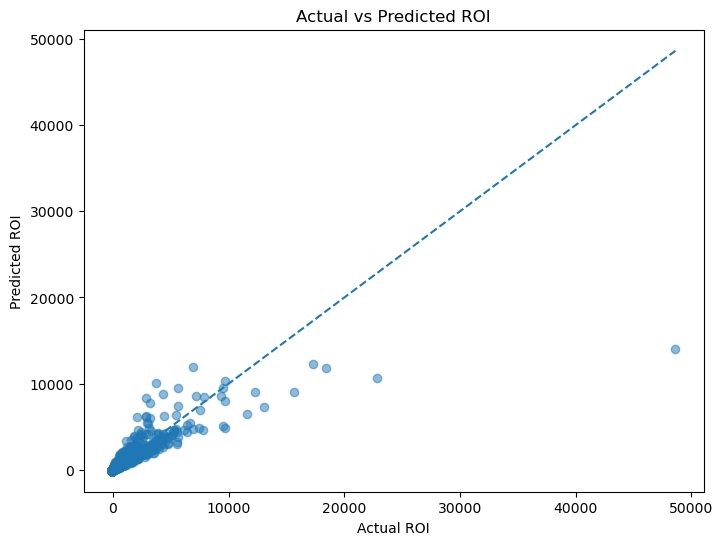

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_tuned, alpha=0.5)

plt.xlabel("Actual ROI")
plt.ylabel("Predicted ROI")
plt.title("Actual vs Predicted ROI")

# Perfect prediction line
min_value = min(y_test.min(), y_pred_tuned.min())
max_value = max(y_test.max(), y_pred_tuned.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

In [22]:
joblib.dump(
    best_rf_model,
    "../models/best_roi_model.pkl"
)

print("Final ROI model saved successfully.")

Final ROI model saved successfully.


In [23]:
final_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R² Score"],
    "Score": [
        mae_tuned,
        rmse_tuned,
        r2_tuned
    ]
})

print("FINAL ROI MODEL PERFORMANCE")
print("===========================")
print("Model: Tuned Random Forest")
print("")

final_results

FINAL ROI MODEL PERFORMANCE
Model: Tuned Random Forest



,Metric,Score
0,MAE,255.778579
1,RMSE,1011.299577
2,R² Score,0.688343


In [24]:
# Step 23 - Save Model Information

model_info = {
    "model": "Tuned Random Forest Regressor",
    "n_estimators": 200,
    "max_depth": 10,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "MAE": mae_tuned,
    "RMSE": rmse_tuned,
    "R2": r2_tuned
}

joblib.dump(
    model_info,
    "../models/roi_model_info.pkl"
)

print("Model information saved successfully.")

Model information saved successfully.


In [25]:
sample_prediction = best_rf_model.predict(
    X_test_processed[:1]
)

print("Actual ROI:", y_test.iloc[0])
print("Predicted ROI:", sample_prediction[0])

Actual ROI: 57.6031244188209
Predicted ROI: 39.82032816076644


In [26]:
test_results = pd.DataFrame({
    "Actual ROI": y_test.values[:20],
    "Predicted ROI": y_pred_tuned[:20]
})

test_results["Absolute Error"] = abs(
    test_results["Actual ROI"] - test_results["Predicted ROI"]
)

test_results

,Actual ROI,Predicted ROI,Absolute Error
0,57.603124,39.820328,17.782796
1,-59.525448,-32.999529,26.525919
2,41.749090,73.978007,32.228917
3,181.677751,316.221144,134.543393
4,549.992619,940.918629,390.926009
5,-59.911716,-39.252270,20.659446
6,-39.600333,-53.503834,13.903501
7,806.227602,1236.977906,430.750303
8,-8.109489,109.669366,117.778855
9,1514.685908,1809.049166,294.363258


In [27]:
from sklearn.ensemble import ExtraTreesRegressor

extra_model = ExtraTreesRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

extra_model.fit(
    X_train_processed,
    y_train
)

print("Extra Trees trained successfully.")

Extra Trees trained successfully.


In [28]:
y_pred_extra = extra_model.predict(X_test_processed)

print("First 10 Extra Trees predictions:")
print(y_pred_extra[:10])

First 10 Extra Trees predictions:
[  17.1812561   -19.91219806  177.44303905  426.49193718  846.93337403
  -39.20387452  -38.24706965 1389.09516049  114.2152102  1681.5719742 ]


In [29]:
mae_extra = mean_absolute_error(y_test, y_pred_extra)

rmse_extra = np.sqrt(
    mean_squared_error(y_test, y_pred_extra)
)

r2_extra = r2_score(y_test, y_pred_extra)

print("Extra Trees Performance")
print("--------------------------------")
print("MAE :", mae_extra)
print("RMSE:", rmse_extra)
print("R²  :", r2_extra)

Extra Trees Performance
--------------------------------
MAE : 258.5494242035576
RMSE: 1039.818663048029
R²  : 0.6705177107185811


In [30]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gradient_model.fit(
    X_train_processed,
    y_train
)

print("Gradient Boosting trained successfully.")

Gradient Boosting trained successfully.


In [31]:
y_pred_gradient = gradient_model.predict(X_test_processed)

print("First 10 Gradient Boosting predictions:")
print(y_pred_gradient[:10])

First 10 Gradient Boosting predictions:
[ -45.41173056 -118.75891798  113.38987478  365.6334208   825.15748466
  -35.05576873  -19.97906213 1186.99800606   88.03093067 1440.78318555]


In [32]:
mae_gradient = mean_absolute_error(
    y_test,
    y_pred_gradient
)

rmse_gradient = np.sqrt(
    mean_squared_error(y_test, y_pred_gradient)
)

r2_gradient = r2_score(
    y_test,
    y_pred_gradient
)

print("Gradient Boosting Performance")
print("--------------------------------")
print("MAE :", mae_gradient)
print("RMSE:", rmse_gradient)
print("R²  :", r2_gradient)

Gradient Boosting Performance
--------------------------------
MAE : 277.3854904281479
RMSE: 944.9041995428245
R²  : 0.7279226323675339


In [34]:
param_grid_gb = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search_gb = GridSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=42
    ),
    param_grid=param_grid_gb,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

grid_search_gb.fit(
    X_train_processed,
    y_train
)

print("Best Gradient Boosting parameters:")
print(grid_search_gb.best_params_)

print("\nBest CV MAE:")
print(-grid_search_gb.best_score_)

Fitting 3 folds for each of 108 candidates, totalling 324 fits
Best Gradient Boosting parameters:
{'learning_rate': 0.03, 'max_depth': 4, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 300}

Best CV MAE:
233.27599692859118


In [35]:
best_gb_model = grid_search_gb.best_estimator_

print("Best Gradient Boosting model:")
print(best_gb_model)

Best Gradient Boosting model:
GradientBoostingRegressor(learning_rate=0.03, max_depth=4, min_samples_leaf=2,
                          min_samples_split=5, n_estimators=300,
                          random_state=42)


In [36]:
y_pred_gb_tuned = best_gb_model.predict(X_test_processed)

mae_gb_tuned = mean_absolute_error(
    y_test,
    y_pred_gb_tuned
)

rmse_gb_tuned = np.sqrt(
    mean_squared_error(y_test, y_pred_gb_tuned)
)

r2_gb_tuned = r2_score(
    y_test,
    y_pred_gb_tuned
)

print("Tuned Gradient Boosting Performance")
print("------------------------------------")
print("MAE :", mae_gb_tuned)
print("RMSE:", rmse_gb_tuned)
print("R²  :", r2_gb_tuned)

Tuned Gradient Boosting Performance
------------------------------------
MAE : 253.02082353270362
RMSE: 905.1450377228283
R²  : 0.7503375612826365


In [37]:
joblib.dump(
    best_gb_model,
    "../models/best_roi_model.pkl"
)

print("Final ROI model saved successfully.")

Final ROI model saved successfully.


In [38]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Random Forest",
        "Extra Trees",
        "Gradient Boosting",
        "Tuned Gradient Boosting"
    ],
    "MAE": [
        mae_linear,
        mae_tree,
        mae_forest,
        mae_tuned,
        mae_extra,
        mae_gradient,
        mae_gb_tuned
    ],
    "RMSE": [
        rmse_linear,
        rmse_tree,
        rmse_forest,
        rmse_tuned,
        rmse_extra,
        rmse_gradient,
        rmse_gb_tuned
    ],
    "R2 Score": [
        r2_linear,
        r2_tree,
        r2_forest,
        r2_tuned,
        r2_extra,
        r2_gradient,
        r2_gb_tuned
    ]
})

final_model_comparison.sort_values(
    by="R2 Score",
    ascending=False
)

,Model,MAE,RMSE,R2 Score
6,Tuned Gradient Boosting,253.020824,905.145038,0.750338
5,Gradient Boosting,277.385490,944.904200,0.727923
3,Tuned Random Forest,255.778579,1011.299577,0.688343
2,Random Forest,256.184717,1027.263612,0.678426
4,Extra Trees,258.549424,1039.818663,0.670518
1,Decision Tree,338.238698,1233.525165,0.536326
0,Linear Regression,547.869892,1437.590399,0.370222


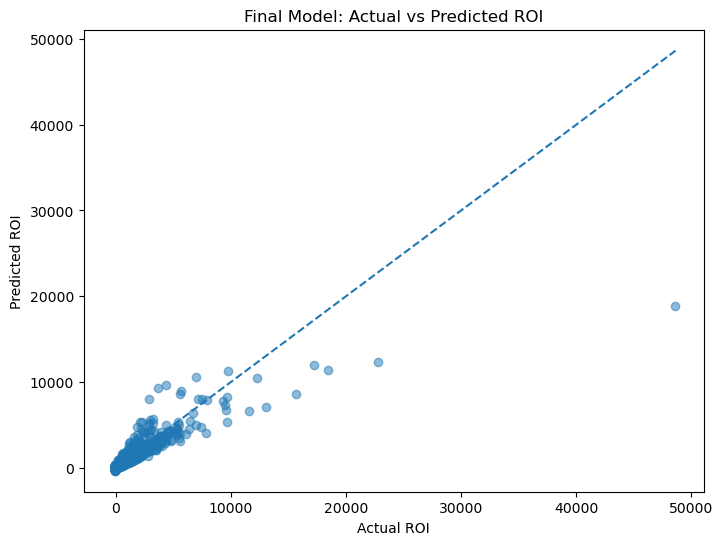

In [39]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_gb_tuned,
    alpha=0.5
)

plt.xlabel("Actual ROI")
plt.ylabel("Predicted ROI")
plt.title("Final Model: Actual vs Predicted ROI")

min_value = min(
    y_test.min(),
    y_pred_gb_tuned.min()
)

max_value = max(
    y_test.max(),
    y_pred_gb_tuned.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

In [40]:
random_indices = np.random.RandomState(42).choice(
    len(y_test),
    size=10,
    replace=False
)

final_test_results = pd.DataFrame({
    "Actual ROI": y_test.iloc[random_indices].values,
    "Predicted ROI": y_pred_gb_tuned[random_indices]
})

final_test_results["Absolute Error"] = abs(
    final_test_results["Actual ROI"]
    - final_test_results["Predicted ROI"]
)

final_test_results

,Actual ROI,Predicted ROI,Absolute Error
0,1162.505675,785.376689,377.128986
1,107.026685,216.693311,109.666627
2,-62.625880,-15.595518,47.030362
3,-10.648403,24.296858,34.945261
4,1161.823490,1049.756863,112.066628
5,246.028022,263.409129,17.381107
6,7.082809,88.767599,81.684790
7,21.193695,11.920757,9.272938
8,63.149489,55.105296,8.044194
9,-31.914691,-4.854765,27.059927
